# UE Data Mining - Projet 2026-2027
## Rapport d'Étape 1 : Nettoyage et Compréhension Initiale des Données
### Application Méthodologique du Cours 1 : *Cleaning and Basic Statistics*

---
* **Master :** M2 Intelligence Artificielle (IA) & M2 Data Science (DS)
* **Nom du groupe :** [Nom du Groupe à compléter]
* **Membres du groupe :**
    * [Prénom NOM 1]
    * [Prénom NOM 2]
    * [Prénom NOM 3]
* **Date :** Année universitaire 2026-2027
---

### Note Méthodologique Fondamentale
Conformément aux principes de rigueur scientifique et aux directives du projet :
1. **Intégrité absolue des données :** Toutes les opérations d'audit, de nettoyage, de transformation et de statistique sont effectuées exclusivement en mémoire. **Aucun fichier source sur disque n'est écrasé ni altéré.**
2. **Structure systématique du rapport :** Chaque étape suit scrupuleusement la structure demandée :
   * **Description de ce que nous allons faire :** Définition précise des opérations et des méthodes appliquées.
   * **Pourquoi nous le faisons :** Justification théorique issue du Cours 1, analyse des impacts sur la qualité de la fouille de données et prise en compte des biais introduits.
   * **Implémentation en code :** Code Python reproductible, documenté et exécuté illustrant concrètement le traitement sur les données réelles du projet.


## 1. Introduction & Cadre Méthodologique

### 1.1 Contexte du Projet et Enjeux du Data Mining
Le projet de l'UE Data Mining nous plonge au cœur d'un univers synthétique complexe constitué de 4 domaines complémentaires :
* `data/ecology/` : Données environnementales, suivis d'espèces (chiroptères), stations météo et réserves.
* `data/health/` : Données médicales, consultations cliniques, examens cardiaques et observations physiologiques.
* `data/logistics/` : Données de chaînes d'approvisionnement, expéditions, réceptions et inventaires d'entreprises.
* `data/public_records/` : Documents administratifs, registres légaux, agréments d'installations et événements réglementaires.

L'objectif final est d'extraire le **narratif caché** à l'intérieur de ces données. Mais avant de pouvoir chercher des motifs complexes ou des associations entre domaines, nous devons franchir l'étape préliminaire et indispensable : **nettoyer et comprendre les données**.

### 1.2 Le Constat du Cours 1 : "Les données réelles, c'est le bordel" (Slide 3)
Dans toute situation réelle ou réaliste de collecte de données, les jeux de données bruts souffrent de défauts majeurs :
1. **Données manquantes (Missing values)** : Enregistrements incomplets, capteurs défaillants ou formulaires partiels.
2. **Formats inconsistants** : Formats de dates hétérogènes, séparateurs décimaux francophones (virgules `,`) et unités textuelles incorporées dans les valeurs numériques.
3. **Valeurs aberrantes (Outliers)** : Erreurs d'encodage ou anomalies extrêmes.
4. **Redondances** : Lignes dupliquées et colonnes répétitives.
5. **Incohérences catégorielles** : Variabilité de la casse, espaces résiduels, synonymes pour un même concept.

### 1.3 Thèse Épistémologique (Slide 10) : Nettoyer c'est Choisir, et Choisir c'est Introduire des Biais
Comme le rappelle le Cours 1 :
> *« Nettoyer des données => Choisir. Choisir => introduire des biais. Donc, nettoyer des données nécessite de bien les comprendre. Une variable qu'on ne comprend pas, il vaut mieux éviter de baser des conclusions dessus. »*

De surcroît, dans le cadre d'un projet d'investigation de narratif caché, **un outlier n'est pas forcément une erreur à détruire** : c'est potentiellement une anomalie révélatrice (une expédition illégale, une contamination biologique anormale, un événement réglementaire suspect). Notre méthodologie privilégiera donc l'étiquetage et la traçabilité plutôt que la suppression brutale.

## 2. Inventaire Global & Ingestion Sécurisée des Données

### 2.1 Description de ce que nous allons faire
* Nous allons analyser la structure globale du répertoire `data/` et parcourir le dictionnaire de données `data/data_dictionary.csv`.
* Nous allons charger les tables clés des différents domaines en mémoire via `pandas` en appliquant le principe d'**immutabilité des sources** : chaque DataFrame sera manipulé via des copies de travail (`df.copy()`).
* Nous produirons un inventaire synthétique récapitulant le nombre de lignes, le nombre de colonnes, l'empreinte mémoire et le volume de valeurs manquantes pour chaque fichier.

### 2.2 Pourquoi nous le faisons
* **Cartographie préalable :** Avant d'appliquer un nettoyage ciblé, il est indispensable de connaître la volumétrie et les liaisons potentielles (clés primaires/étrangères définies dans le dictionnaire).
* **Préservation des données brutes :** Dans une démarche scientifique, les données sources doivent demeurer intactes pour garantir la reproductibilité intégrale et permettre de retester différentes hypothèses sans altérer le terrain de départ.
* **Audit initial du désordre :** Cet inventaire permet d'identifier immédiatement les tables les plus affectées par les valeurs manquantes et le volume de travail à fournir.

In [1]:
# Configuration de l'environnement de travail
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Paramètres d'affichage esthétiques
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

print("Environnement configuré avec succès.")

Environnement configuré avec succès.


In [2]:
# Inventaire complet des jeux de données et du dictionnaire
data_root = "data"
dict_path = os.path.join(data_root, "data_dictionary.csv")

if os.path.exists(dict_path):
    data_dict = pd.read_csv(dict_path)
    print(f"Dictionnaire de données chargé : {len(data_dict)} entrées couvrant {data_dict['file_name'].nunique()} fichiers.")
else:
    print("Attention : data_dictionary.csv introuvable.")

# Audit global de tous les fichiers CSV
records = []
for domain in ['ecology', 'health', 'logistics', 'public_records']:
    files = glob.glob(os.path.join(data_root, domain, "*.csv"))
    for f in sorted(files):
        df_raw = pd.read_csv(f)
        records.append({
            'Domaine': domain,
            'Fichier': os.path.basename(f),
            'Lignes': df_raw.shape[0],
            'Colonnes': df_raw.shape[1],
            'Valeurs Manquantes': df_raw.isna().sum().sum(),
            'Taux Manquant (%)': round(df_raw.isna().sum().sum() / (df_raw.shape[0] * df_raw.shape[1]) * 100, 2),
            'Doublons Stricts': df_raw.duplicated().sum(),
            'Mémoire (Ko)': round(df_raw.memory_usage(deep=True).sum() / 1024, 1)
        })

df_inventory = pd.DataFrame(records)
print("=== INVENTAIRE GLOBAL DES JEUX DE DONNÉES DU PROJET ===")
display(df_inventory.head(15))
print(f"Total fichiers analysés : {len(df_inventory)} | Total lignes : {df_inventory['Lignes'].sum():,}")

Dictionnaire de données chargé : 355 entrées couvrant 29 fichiers.
=== INVENTAIRE GLOBAL DES JEUX DE DONNÉES DU PROJET ===


,Domaine,Fichier,Lignes,Colonnes,Valeurs Manquantes,Taux Manquant (%),Doublons Stricts,Mémoire (Ko)
0,ecology,bat_surveys.csv,4994,14,20,0.03,2,3920.8
1,ecology,environmental_field_reports.csv,30,12,1,0.28,0,63.8
2,ecology,environmental_monthly.csv,4994,11,4815,8.77,2,2203.0
3,ecology,monitoring_device_operations.csv,4994,11,4835,8.80,2,3236.1
4,ecology,monitoring_sites.csv,64,14,65,7.25,0,47.6
5,ecology,orchard_surveys.csv,1250,11,1227,8.92,2,614.1
6,health,cardiac_recordings.csv,44,19,0,0.00,0,40.6
7,health,cardiac_signal_samples.csv,96925,4,0,0.00,0,8613.6
8,health,clinical_encounters.csv,1069,12,243,1.89,2,887.1
9,health,clinical_notes.csv,30,11,30,9.09,0,62.1


Total fichiers analysés : 29 | Total lignes : 136,143


## 3. Nettoyer ses Données : Gérer les Redondances d'Informations (Slide 5)

### 3.1 Description de ce que nous allons faire
* **Lignes :** Détecter systématiquement les lignes strictement dupliquées au sein de chaque table à l'aide de la méthode `df.duplicated()` et examiner si les identifiants clés présentent des collisions. Nous éliminerons les doublons stricts en conservant la première occurrence (`keep='first'`).
* **Colonnes :** Analyser les paires de colonnes potentiellement redondantes (par exemple : nom complet vs nom + prénom, ou date de naissance vs âge, ou identifiant de site vs nom de site).
* Nous appliquerons scrupuleusement la règle du Cours 1 :
  * Si pas de données manquantes : **privilégier le niveau de détail**.
  * En présence de données manquantes : **privilégier la colonne sans données manquantes**.

### 3.2 Pourquoi nous le faisons
* **Biais statistique des doublons :** La présence de lignes répétées fausse l'intégralité des mesures descriptives : elle tire artificiellement la moyenne vers les valeurs dupliquées, diminue artificiellement la variance et crée des corrélations trompeuses.
* **Intégrité relationnelle :** Pour les jointures ultérieures (par exemple entre `bat_surveys` et `monitoring_sites` via `site_code`), un doublon génère un produit cartésien qui multiplie les observations à l'insu de l'analyste.
* **Efficacité & Clarté :** Éliminer la redondance entre colonnes allège le modèle conceptuel et prévient les contradictions internes lors de l'analyse exploratoire.

In [3]:
# 1. Détection et traitement des doublons de lignes
# Démonstration sur des tables clés issues de différents domaines

tables_to_dedup = {
    'bat_surveys': 'data/ecology/bat_surveys.csv',
    'clinical_encounters': 'data/health/clinical_encounters.csv',
    'clinical_observations': 'data/health/clinical_observations.csv',
    'shipments': 'data/logistics/shipments.csv',
    'patient_administration': 'data/health/patient_administration.csv'
}

cleaned_dfs = {}
dedup_summary = []

for name, path in tables_to_dedup.items():
    raw_df = pd.read_csv(path)
    n_initial = len(raw_df)
    n_dups = raw_df.duplicated().sum()
    
    # Déduplication en mémoire (préservation du fichier original)
    clean_df = raw_df.drop_duplicates(keep='first').copy()
    cleaned_dfs[name] = clean_df
    
    dedup_summary.append({
        'Table': name,
        'Lignes initiales': n_initial,
        'Doublons détectés': n_dups,
        'Lignes après nettoyage': len(clean_df),
        'Pourcentage conservé': f"{(len(clean_df) / n_initial)*100:.2f}%"
    })

df_dedup_res = pd.DataFrame(dedup_summary)
print("=== RÉSULTATS DE LA DÉDUPLICATION DES LIGNES (Slide 5) ===")
display(df_dedup_res)

# Exemple concret : Affichage d'un doublon exact détecté avant suppression
bat_raw = pd.read_csv('data/ecology/bat_surveys.csv')
dup_mask = bat_raw.duplicated(keep=False)
if dup_mask.sum() > 0:
    print("\nExemple de lignes doublons identifiées dans bat_surveys.csv :")
    display(bat_raw[dup_mask].head(4))

=== RÉSULTATS DE LA DÉDUPLICATION DES LIGNES (Slide 5) ===


,Table,Lignes initiales,Doublons détectés,Lignes après nettoyage,Pourcentage conservé
0,bat_surveys,4994,2,4992,99.96%
1,clinical_encounters,1069,2,1067,99.81%
2,clinical_observations,17736,2,17734,99.99%
3,shipments,452,2,450,99.56%
4,patient_administration,241,1,240,99.59%



Exemple de lignes doublons identifiées dans bat_surveys.csv :


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
3182,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
3566,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9
4992,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
4993,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9


In [4]:
# 2. Analyse de la redondance au niveau des colonnes (Slide 5)
# Règle du cours : Si pas de données manquantes -> privilégier le détail ; sinon -> colonne sans valeurs manquantes

pat_df = pd.read_csv('data/health/patient_administration.csv').drop_duplicates()
print("Vérification des colonnes identitaires dans patient_administration.csv :")
print(f"Colonnes disponibles : {pat_df.columns.tolist()}\n")

# Vérification de l'unicité de la clé primaire
print(f"Nombre total de patients : {len(pat_df)}")
print(f"Identifiants uniques 'patient_number' : {pat_df['patient_number'].nunique()}")
print(f"Valeurs manquantes sur family_name : {pat_df['family_name'].isna().sum()}")
print(f"Valeurs manquantes sur given_name : {pat_df['given_name'].isna().sum()}")

# Application méthodologique :
# Si une table contenait 'full_name' ET ('family_name', 'given_name'),
# comme family_name et given_name n'ont 0 valeurs manquantes, la règle du cours impose
# de conserver les deux colonnes détaillées qui offrent un pouvoir séparateur supérieur.

Vérification des colonnes identitaires dans patient_administration.csv :
Colonnes disponibles : ['patient_number', 'family_name', 'given_name', 'date_of_birth', 'registered_sex', 'home_region', 'occupation_text', 'registration_date', 'primary_facility_license', 'record_status']

Nombre total de patients : 240
Identifiants uniques 'patient_number' : 240
Valeurs manquantes sur family_name : 0
Valeurs manquantes sur given_name : 0


## 4. Nettoyer ses Données : Gérer les Formats Inconsistants (Slide 6)

### 4.1 Description de ce que nous allons faire
Dans cette étape, nous identifions et rectifions les deux anomalies majeures de formatage présentes dans les jeux de données :
1. **Les colonnes numériques polluées :**
   * Présence de séparateurs décimaux francophones (virgules `,` au lieu de points `.`).
   * Suffixes textuels et unités injectés directement dans les cellules de mesure (ex: `' count'`, `' bpm'`, `' index'`, `' %'`, `' L/min'`).
   * Ces colonnes sont chargées comme `object` (chaînes de caractères) par pandas.
2. **Les dates et horodatages hétérogènes :**
   * Présence de formats multiples : `YYYY-MM-DD`, `YYYY-MM-DDTHH:MM:SS`, dates avec fuseaux ou heures tronquées.
   * Nous standardiserons toutes les colonnes temporelles au format international ISO 8601 via `pd.to_datetime()`.

### 4.2 Pourquoi nous le faisons
* **Déblocage du calcul mathématique :** Une colonne de type `object` ne permet aucun calcul de moyenne, de variance, de médiane ou de corrélation. Tout appel à une fonction statistique renvoie une erreur ou une concaténation de texte.
* **Respect des bonnes pratiques du Cours (Slide 6) :**
  * *« Choisir le format le plus précis et convertir les autres valeurs de la colonne. »*
  * *« Choisir l'unité de mesure la plus commune et convertir les autres valeurs OU faire une colonne par unité. »*
* **Rapprochement temporel multi-sources :** Pour croiser les observations cliniques avec les relevés environnementaux et les expéditions logistiques, il est impératif d'avoir une échelle temporelle commune et normalisée.

In [5]:
# Fonction robuste de nettoyage des valeurs numériques polluées
def clean_numeric_series(series, remove_units=True):
    """
    Nettoie une série pandas contenant des nombres au format texte,
    avec virgules décimales et suffixes d'unités éventuels.
    """
    if pd.api.types.is_numeric_dtype(series):
        return series
    
    # 1. Remplacement des virgules par des points
    s = series.astype(str).str.strip().str.replace(',', '.', regex=False)
    
    # 2. Extraction du pattern numérique (gère les entiers, flottants et signes négatifs)
    pattern = r'([-+]?\d*\.?\d+)'
    extracted = s.str.extract(pattern, expand=False)
    
    # 3. Conversion en float
    return pd.to_numeric(extracted, errors='coerce')

# Application sur bat_surveys
bat_clean = cleaned_dfs['bat_surveys'].copy()
numeric_cols_bat = ['observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'nightly_visit_count', 'weather_interference']

print("=== AVANT NETTOYAGE DANS bat_surveys.csv ===")
print(bat_clean[numeric_cols_bat].dtypes)
print("\nÉchantillon brut avec virgules et unités :")
display(bat_clean[numeric_cols_bat].head(3))

for col in numeric_cols_bat:
    bat_clean[col] = clean_numeric_series(bat_clean[col])

print("\n=== APRÈS NETTOYAGE DANS bat_surveys.csv ===")
print(bat_clean[numeric_cols_bat].dtypes)
print("\nStatistiques descriptives débloquées :")
display(bat_clean[numeric_cols_bat].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])
cleaned_dfs['bat_surveys'] = bat_clean

=== AVANT NETTOYAGE DANS bat_surveys.csv ===
observation_hours           object
observed_bat_count          object
acoustic_detection_count    object
nightly_visit_count         object
weather_interference        object
dtype: object

Échantillon brut avec virgules et unités :


,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,weather_interference
0,28.6,7,13,7,32.0
1,31.7,8,12,9,18.5
2,32.4,22,28,14,26.2



=== APRÈS NETTOYAGE DANS bat_surveys.csv ===
observation_hours           float64
observed_bat_count            int64
acoustic_detection_count      int64
nightly_visit_count           int64
weather_interference        float64
dtype: object

Statistiques descriptives débloquées :


,count,mean,std,min,50%,max
observation_hours,4992.0,30.327524,5.504168,5.0,30.6,46.9
observed_bat_count,4992.0,14.127604,8.248394,0.0,13.0,73.0
acoustic_detection_count,4992.0,20.480970,12.128314,0.0,18.0,107.0
nightly_visit_count,4992.0,10.107973,6.062931,0.0,9.0,54.0
weather_interference,4992.0,37.486058,16.657117,0.0,36.7,100.0


In [6]:
# Application sur clinical_observations.csv
obs_clean = cleaned_dfs['clinical_observations'].copy()

print("Démonstration du nettoyage sur clinical_observations.csv :")
print(f"Type initial de 'numeric_value' : {obs_clean['numeric_value'].dtype}")
sample_polluted = obs_clean[obs_clean['numeric_value'].astype(str).str.contains(r'[,%a-zA-Z]', regex=True)]['numeric_value'].head(5)
print(f"Exemples de valeurs polluées détectées :\n{sample_polluted.tolist()}\n")

# Conversion propre
obs_clean['numeric_value_cleaned'] = clean_numeric_series(obs_clean['numeric_value'])
print(f"Nombre de valeurs converties avec succès : {obs_clean['numeric_value_cleaned'].notna().sum():,} / {len(obs_clean):,}")
print(f"Type final : {obs_clean['numeric_value_cleaned'].dtype}")
display(obs_clean[['observation_name', 'numeric_value', 'numeric_value_cleaned', 'unit']].head(6))

cleaned_dfs['clinical_observations'] = obs_clean

Démonstration du nettoyage sur clinical_observations.csv :
Type initial de 'numeric_value' : object
Exemples de valeurs polluées détectées :
[nan, nan, '84,9', nan, nan]

Nombre de valeurs converties avec succès : 15,864 / 17,734
Type final : float64


,observation_name,numeric_value,numeric_value_cleaned,unit
0,Resting pulse,64.0,64.00,bpm
1,Apical cardiac rate,88.5,88.50,bpm
2,Peripheral pulse rate,75.8,75.80,bpm
3,Estimated cardiac output,5.57,5.57,L/min
4,Peripheral oxygen saturation,97.2,97.20,%
5,Thoracic vibration index,82.5,82.50,index


In [7]:
# Standardisation des dates et horodatages au format ISO 8601
# Application sur shipments.csv et bat_surveys.csv

shipments_clean = cleaned_dfs['shipments'].copy()

print("=== HARMONISATION TEMPORELLE ===")
print("Format initial dispatch_time (échantillon) :", shipments_clean['dispatch_time'].head(2).tolist())

shipments_clean['dispatch_time_dt'] = pd.to_datetime(shipments_clean['dispatch_time'], errors='coerce')
shipments_clean['arrival_time_dt'] = pd.to_datetime(shipments_clean['arrival_time'], errors='coerce')

# Calcul d'une variable dérivée vérifiable : durée de transit en heures
shipments_clean['transit_hours'] = (shipments_clean['arrival_time_dt'] - shipments_clean['dispatch_time_dt']).dt.total_seconds() / 3600

print(f"Dates converties avec succès. Échantillon après transformation :")
display(shipments_clean[['shipment_number', 'dispatch_time_dt', 'arrival_time_dt', 'transit_hours']].head(4))
cleaned_dfs['shipments'] = shipments_clean

=== HARMONISATION TEMPORELLE ===
Format initial dispatch_time (échantillon) : ['2014-07-10T09:00:00', '2015-01-10T11:00:00']
Dates converties avec succès. Échantillon après transformation :


,shipment_number,dispatch_time_dt,arrival_time_dt,transit_hours
0,SHP-2014-00001,2014-07-10 09:00:00,2014-07-11 03:00:00,18.0
1,SHP-2015-00001,2015-01-10 11:00:00,2015-01-13 16:00:00,77.0
2,SHP-2015-00002,2015-01-11 06:00:00,2015-01-12 00:00:00,18.0
3,SHP-2015-00003,2015-02-17 15:00:00,2015-02-19 08:00:00,41.0


## 5. Nettoyer ses Données : Variables Catégorielles & Encodage (Slides 7 & 8)

### 5.1 Description de ce que nous allons faire
* **Normalisation des chaînes de caractères :**
  1. Suppression des espaces de début et de fin (`strip()`).
  2. Remplacement des espaces multiples internes par un espace simple (`re.sub(r'\s+', ' ', text)`).
  3. Harmonisation de la casse (passage en minuscules pour comparaison, ou format titre standardisé).
* **Fusion des labels synonymes ou fautifs :** Identifier les variantes orthographiques désignant un même concept (ex: `'Delivered'`, `'DELIVERED'`, `'delivered'`) et les mapper vers un libellé canonique unique.
* **Bonus Encodage (Slide 8) :**
  * Comparer le **One-Hot Encoding** (une colonne binaire par modalité) et le **Dummy Encoding** (`drop_first=True`, évitant le piège de la multi-collinéarité pour les modèles linéaires).

### 5.2 Pourquoi nous le faisons
* **Fragmentation artificielle des modalités :** Pour un algorithme ou une table de contingence, `'delivered'`, `'Delivered '` et `'DELIVERED'` sont trois états mutuellement exclusifs. Cette incohérence divise le support statistique et dissimule les véritables relations.
* **Bonnes pratiques du Cours 1 (Slide 7) :**
  1. Identifier les différents noms utilisés pour un même « objet ».
  2. Choisir le label le plus adapté parmi ces noms.
  3. Remplacer le reste par le label choisi.
* **Préparation pour la fouille de motifs et le machine learning :** Les algorithmes nécessitent des représentations numériques rigoureuses des attributs nominaux.

In [8]:
# Fonction de nettoyage et normalisation des variables catégorielles
def clean_categorical_series(series, case_mode='lower'):
    """
    Nettoie les chaînes d'une série catégorielle :
    - Supprime les espaces en tête/queue
    - Réduit les espaces multiples consécutifs
    - Harmonise la casse ('lower', 'upper', ou 'title')
    """
    if not pd.api.types.is_object_dtype(series):
        return series
    
    s = series.astype(str).str.strip()
    s = s.str.replace(r'\s+', ' ', regex=True)
    
    if case_mode == 'lower':
        s = s.str.lower()
    elif case_mode == 'upper':
        s = s.str.upper()
    elif case_mode == 'title':
        s = s.str.title()
        
    # Restaure les NaN originaux
    s[series.isna()] = np.nan
    return s

# Application sur shipments.csv -> shipment_status
shp = cleaned_dfs['shipments'].copy()
print("=== DÉMONSTRATION DANS shipments.csv (shipment_status) ===")
print("Modalités AVANT harmonisation :")
print(shp['shipment_status'].value_counts(dropna=False))

shp['shipment_status_cleaned'] = clean_categorical_series(shp['shipment_status'], case_mode='lower')

print("\nModalités APRÈS harmonisation canonique :")
print(shp['shipment_status_cleaned'].value_counts(dropna=False))
cleaned_dfs['shipments'] = shp

=== DÉMONSTRATION DANS shipments.csv (shipment_status) ===
Modalités AVANT harmonisation :
shipment_status
delivered     381
delayed        33
in_transit     17
returned       14
DELIVERED       3
Delivered       1
DELAYED         1
Name: count, dtype: int64

Modalités APRÈS harmonisation canonique :
shipment_status_cleaned
delivered     385
delayed        34
in_transit     17
returned       14
Name: count, dtype: int64


In [9]:
# Application sur patient_administration.csv -> home_region et record_status
pat = cleaned_dfs['patient_administration'].copy()

print("=== DÉMONSTRATION DANS patient_administration.csv ===")
print("Valeurs brutes de 'home_region' :")
print(pat['home_region'].unique().tolist())

# Correction des inversions de casse bizarres (ex: 'vALENNE rEPUBLIC')
pat['home_region_clean'] = pat['home_region'].astype(str).str.strip().str.title()
pat['record_status_clean'] = clean_categorical_series(pat['record_status'], case_mode='lower')

print("\nValeurs nettoyées de 'home_region' :")
print(pat['home_region_clean'].unique().tolist())
print("\nValeurs nettoyées de 'record_status' :")
print(pat['record_status_clean'].value_counts())
cleaned_dfs['patient_administration'] = pat

=== DÉMONSTRATION DANS patient_administration.csv ===
Valeurs brutes de 'home_region' :
['Valenne Republic', 'Nordhaven Union', 'Avelora Federation', 'Kintara Republic', 'Tembara Commonwealth', 'vALENNE rEPUBLIC']

Valeurs nettoyées de 'home_region' :
['Valenne Republic', 'Nordhaven Union', 'Avelora Federation', 'Kintara Republic', 'Tembara Commonwealth']

Valeurs nettoyées de 'record_status' :
record_status_clean
active      230
inactive      9
deceased      1
Name: count, dtype: int64


In [10]:
# Démonstration du Bonus Encodage (Slide 8) : One-Hot vs Dummy Encoding
# Sur la variable nominale 'temperature_control_class' de shipments

shp = cleaned_dfs['shipments'].copy()
shp['temperature_control_clean'] = clean_categorical_series(shp['temperature_control_class'], case_mode='lower')

# 1. One-Hot Encoding complet (K colonnes)
ohe_df = pd.get_dummies(shp['temperature_control_clean'], prefix='temp', dtype=int)

# 2. Dummy Encoding (K-1 colonnes, élimine la modalité de référence pour éviter la multi-collinéarité)
dummy_df = pd.get_dummies(shp['temperature_control_clean'], prefix='temp', drop_first=True, dtype=int)

print("=== BONUS ENCODAGE (Slide 8) ===")
print(f"One-Hot Encoding complet : {ohe_df.shape[1]} colonnes créées : {ohe_df.columns.tolist()}")
print(f"Dummy Encoding (drop_first=True) : {dummy_df.shape[1]} colonnes créées : {dummy_df.columns.tolist()}")
print("\nComparaison sur 3 observations :")
display(pd.concat([shp[['temperature_control_clean']].head(3), dummy_df.head(3)], axis=1))

=== BONUS ENCODAGE (Slide 8) ===
One-Hot Encoding complet : 3 colonnes créées : ['temp_2-8c', 'temp_ambient', 'temp_frozen']
Dummy Encoding (drop_first=True) : 2 colonnes créées : ['temp_ambient', 'temp_frozen']

Comparaison sur 3 observations :


,temperature_control_clean,temp_ambient,temp_frozen
0,2-8c,0,0
1,2-8c,0,0
2,ambient,1,0


## 6. Nettoyer ses Données : Données Manquantes & Aberrantes (Slides 9 & 10)

### 6.1 Description de ce que nous allons faire
1. **Cartographie des données manquantes :** Calculer la proportion de valeurs nulles (`NaN`) pour chaque colonne et déterminer les mécanismes sous-jacents (MCAR, MAR, MNAR).
2. **Stratégies de traitement des valeurs manquantes :**
   * *Conservation & Encodage de l'absence :* Considérer que **« l'absence d'information est une information en soi »** (Slide 9). Créer un indicateur binaire de manque (`is_missing`) lorsque l'omission est signifiante.
   * *Imputation adaptée :* Utiliser la **médiane** pour les variables asymétriques à queue lourde (robuste aux valeurs extrêmes) et la **moyenne** uniquement pour les lois parfaitement symétriques.
3. **Détection des valeurs aberrantes (Outliers) :**
   * Calcul des bornes de Tukey basées sur l'intervalle interquartile ($IQR = Q_3 - Q_1$) :
     $$\text{Borne basse} = Q_1 - 1.5 \times IQR, \quad \text{Borne haute} = Q_3 + 1.5 \times IQR$$
   * Évaluation critique : distinguer les erreurs physiques manifestes des véritables anomalies révélatrices d'un phénomène caché.

### 6.2 Pourquoi nous le faisons
* **Préservation contre les distorsions :** Une valeur aberrante extrême (ex: âge de 143 ans ou -99 dans l'exemple du cours) fait exploser la variance et déplace arbitrairement la droite de régression.
* **Avertissement crucial du Cours 1 (Slide 10) :**
  > *« Nettoyer des données => Choisir => introduire des biais... Un outlier peut aussi être une anomalie intéressante à repérer (Cf. cours 2). »*
* Dans notre projet, les anomalies peuvent être des indices clés du narratif criminel ou organisationnel. Nous devons donc **marquer (flaguer)** les outliers sans détruire l'information sous-jacente.

In [11]:
# 1. Audit détaillé des valeurs manquantes sur les tables d'observation
def missing_data_report(df, name="Table"):
    null_counts = df.isna().sum()
    null_pct = (null_counts / len(df)) * 100
    report = pd.DataFrame({'Manquants': null_counts, 'Pourcentage (%)': null_pct})
    report = report[report['Manquants'] > 0].sort_values(by='Pourcentage (%)', ascending=False)
    print(f"=== AUDIT DES VALEURS MANQUANTES : {name} (Total lignes = {len(df)}) ===")
    if len(report) == 0:
        print("Aucune valeur manquante détectée.")
    else:
        display(report.head(10))
    return report

_ = missing_data_report(cleaned_dfs['clinical_observations'], "clinical_observations")
_ = missing_data_report(cleaned_dfs['bat_surveys'], "bat_surveys")

=== AUDIT DES VALEURS MANQUANTES : clinical_observations (Total lignes = 17734) ===


,Manquants,Pourcentage (%)
text_value,15864,89.455284
device_reference,4325,24.388181
numeric_value,1870,10.544716
unit,1870,10.544716
numeric_value_cleaned,1870,10.544716


=== AUDIT DES VALEURS MANQUANTES : bat_surveys (Total lignes = 4992) ===


,Manquants,Pourcentage (%)
observer_team,20,0.400641


In [12]:
# 2. Détection des outliers par la méthode de Tukey (IQR) vs Z-Score
def detect_outliers_iqr(series, k=1.5):
    """
    Détecte les outliers par l'intervalle interquartile de Tukey :
    [Q1 - k*IQR, Q3 + k*IQR]
    """
    s = series.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - k * iqr
    upper_bound = q3 + k * iqr
    
    outliers_mask = (series < lower_bound) | (series > upper_bound)
    return outliers_mask, lower_bound, upper_bound

# Application sur bat_surveys -> observed_bat_count
bat_clean = cleaned_dfs['bat_surveys']
mask_outliers, lb, ub = detect_outliers_iqr(bat_clean['observed_bat_count'])

print(f"=== DÉTECTION DES OUTLIERS SUR 'observed_bat_count' (Tukey IQR) ===")
print(f"Q1 = {bat_clean['observed_bat_count'].quantile(0.25)}, Q3 = {bat_clean['observed_bat_count'].quantile(0.75)}")
print(f"IQR = {bat_clean['observed_bat_count'].quantile(0.75) - bat_clean['observed_bat_count'].quantile(0.25)}")
print(f"Bornes de Tukey : [{lb:.2f}, {ub:.2f}]")
print(f"Nombre d'outliers identifiés : {mask_outliers.sum()} ({mask_outliers.mean()*100:.2f}%)")

# Règle d'or : On ne supprime pas l'outlier, on ajoute un drapeau (flag) analytique
bat_clean['is_bat_count_outlier'] = mask_outliers
print("\nExemple d'outliers étiquetés pour l'investigation du narratif :")
display(bat_clean[mask_outliers][['survey_id', 'site_code', 'survey_start', 'observed_bat_count', 'weather_interference']].head(4))
cleaned_dfs['bat_surveys'] = bat_clean

=== DÉTECTION DES OUTLIERS SUR 'observed_bat_count' (Tukey IQR) ===
Q1 = 8.0, Q3 = 18.0
IQR = 10.0
Bornes de Tukey : [-7.00, 33.00]
Nombre d'outliers identifiés : 128 (2.56%)

Exemple d'outliers étiquetés pour l'investigation du narratif :


,survey_id,site_code,survey_start,observed_bat_count,weather_interference
26,BAT-0000027,KNT-KES,2021-03-05T18:00:00,38,23.3
39,BAT-0000040,KNT-KES,2022-04-05T18:00:00,40,32.7
41,BAT-0000042,KNT-KES,2022-06-05T18:00:00,36,44.3
49,BAT-0000050,KNT-KES,2023-02-05T18:00:00,41,15.5


## 7. Comprendre ses Données : Typologie & Statistiques Descriptives (Slides 11, 12, 13)

### 7.1 Description de ce que nous allons faire
* **Identification des types de variables (Slide 12) :**
  * Numérique Discrète (entiers, comptages, ex: `observed_bat_count`).
  * Numérique Continue (flottants réels, mesures physiques, ex: `observation_hours`, `weather_interference`).
  * Nominale non-ordonnée (ex: `site_code`, `registered_sex`).
  * Nominale ordinale (modalités hiérarchisées, ex: `survey_quality` : `limited` < `acceptable` < `high`).
  * Temporelle (dates / timestamps, ex: `survey_start`).
* **Application stricte des couples de bonnes pratiques statistiques (Slide 13) :**
  * **TOUJOURS associer la Moyenne avec l'Écart-type** ($\mu \pm \sigma$).
  * **TOUJOURS associer la Médiane avec le Min, le Max et les Quartiles** ($	ext{Médiane}, Q_1, Q_3, [	ext{Min}, 	ext{Max}]$).

### 7.2 Pourquoi nous le faisons
* **Protection contre les conclusions hâtives :** Une moyenne isolée est incapable de décrire la dispersion d'une variable. Deux distributions ayant une moyenne de 50 peuvent avoir des écarts-types de 2 ou de 40.
* **Robustesse de la médiane :** Si une variable est asymétrique ou polluée par des outliers, la moyenne est biaisée vers les valeurs extrêmes, tandis que la médiane reste stable. L'association conjointe des deux couples permet un diagnostic immédiat de la symétrie de la distribution.

In [13]:
# Fonction calculant le tableau statistique conforme aux exigences strictes du Cours 1
def course_compliant_statistics(df, numeric_columns):
    """
    Calcule et associe obligatoirement :
    1. Moyenne & Écart-type (pour variables gaussiennes)
    2. Médiane & Min / Max / Quartiles (pour variables robustes)
    """
    stats_list = []
    for col in numeric_columns:
        s = df[col].dropna()
        if len(s) == 0:
            continue
        mean_val = s.mean()
        std_val = s.std()
        median_val = s.median()
        q1_val = s.quantile(0.25)
        q3_val = s.quantile(0.75)
        iqr_val = q3_val - q1_val
        min_val = s.min()
        max_val = s.max()
        skew_val = s.skew()
        
        stats_list.append({
            'Variable': col,
            'Effectif N': len(s),
            'Moyenne': round(mean_val, 3),
            'Écart-type': round(std_val, 3),
            'Couple 1 (Moyenne ± Std)': f"{mean_val:.2f} ± {std_val:.2f}",
            'Médiane': round(median_val, 3),
            'Q1': round(q1_val, 3),
            'Q3': round(q3_val, 3),
            'IQR': round(iqr_val, 3),
            'Min': round(min_val, 3),
            'Max': round(max_val, 3),
            'Couple 2 (Médiane [Q1; Q3])': f"{median_val:.2f} [{q1_val:.2f}; {q3_val:.2f}]",
            'Écart Moyenne - Médiane': round(mean_val - median_val, 3),
            'Asymétrie (Skewness)': round(skew_val, 3)
        })
    return pd.DataFrame(stats_list)

bat_num_cols = ['observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'weather_interference']
df_course_stats = course_compliant_statistics(cleaned_dfs['bat_surveys'], bat_num_cols)

print("=== TABLEAU STATISTIQUE DES VARIABLES NUMÉRIQUES (BONNES PRATIQUES SLIDE 13) ===")
display(df_course_stats[['Variable', 'Couple 1 (Moyenne ± Std)', 'Couple 2 (Médiane [Q1; Q3])', 'Min', 'Max', 'Écart Moyenne - Médiane', 'Asymétrie (Skewness)']])

=== TABLEAU STATISTIQUE DES VARIABLES NUMÉRIQUES (BONNES PRATIQUES SLIDE 13) ===


,Variable,Couple 1 (Moyenne ± Std),Couple 2 (Médiane [Q1; Q3]),Min,Max,Écart Moyenne - Médiane,Asymétrie (Skewness)
0,observation_hours,30.33 ± 5.50,30.60 [26.90; 34.10],5.0,46.9,-0.272,-0.371
1,observed_bat_count,14.13 ± 8.25,13.00 [8.00; 18.00],0.0,73.0,1.128,1.420
2,acoustic_detection_count,20.48 ± 12.13,18.00 [12.00; 26.00],0.0,107.0,2.481,1.444
3,weather_interference,37.49 ± 16.66,36.70 [25.10; 49.00],0.0,100.0,0.786,0.329


## 8. Comprendre ses Données : Lois Normales vs Lois de Puissance & Visualisations (Slides 14 & 15)

### 8.1 Description de ce que nous allons faire
* **Diagnostic distributionnel :** Évaluer si les variables suivent une loi normale (symétrique, $\text{Moyenne} \approx \text{Médiane}$) ou une **loi de puissance (Power Law / queue lourde)** où la moyenne diverge fortement de la médiane.
* **Mise en œuvre des visualisations recommandées (Slide 13 & 15) :**
  * **Histogramme avec estimation de densité par noyau (KDE) :** Toujours obligatoire pour observer la forme de la distribution.
  * **Boîtes à moustaches (Boxplots) :** Visualisation des quartiles et des points extrêmes.
  * **Graphiques en violon (Violin plots) :** Combinaison de la boîte à moustaches et du profil de densité.
  * **Diagrammes en barres (Barplots) :** Répartition des effectifs pour les variables nominales ordonnées ou non.

### 8.2 Pourquoi nous le faisons
* **Le constat de terrain du Cours 1 (Slide 14) :**
  > *« En théorie, toute variable suit une loi normale. En pratique, la plupart des variables suivent une loi de puissance (ou un mix). »*
* Si une variable suit une loi de puissance, l'utilisation de tests gaussiens classiques produira des faux positifs. Identifier la forme de la loi guide le choix de potentielles transformations (ex: passage au logarithme $\log(1+x)$) et conditionne les méthodes de discrétisation ou de clustering ultérieures.

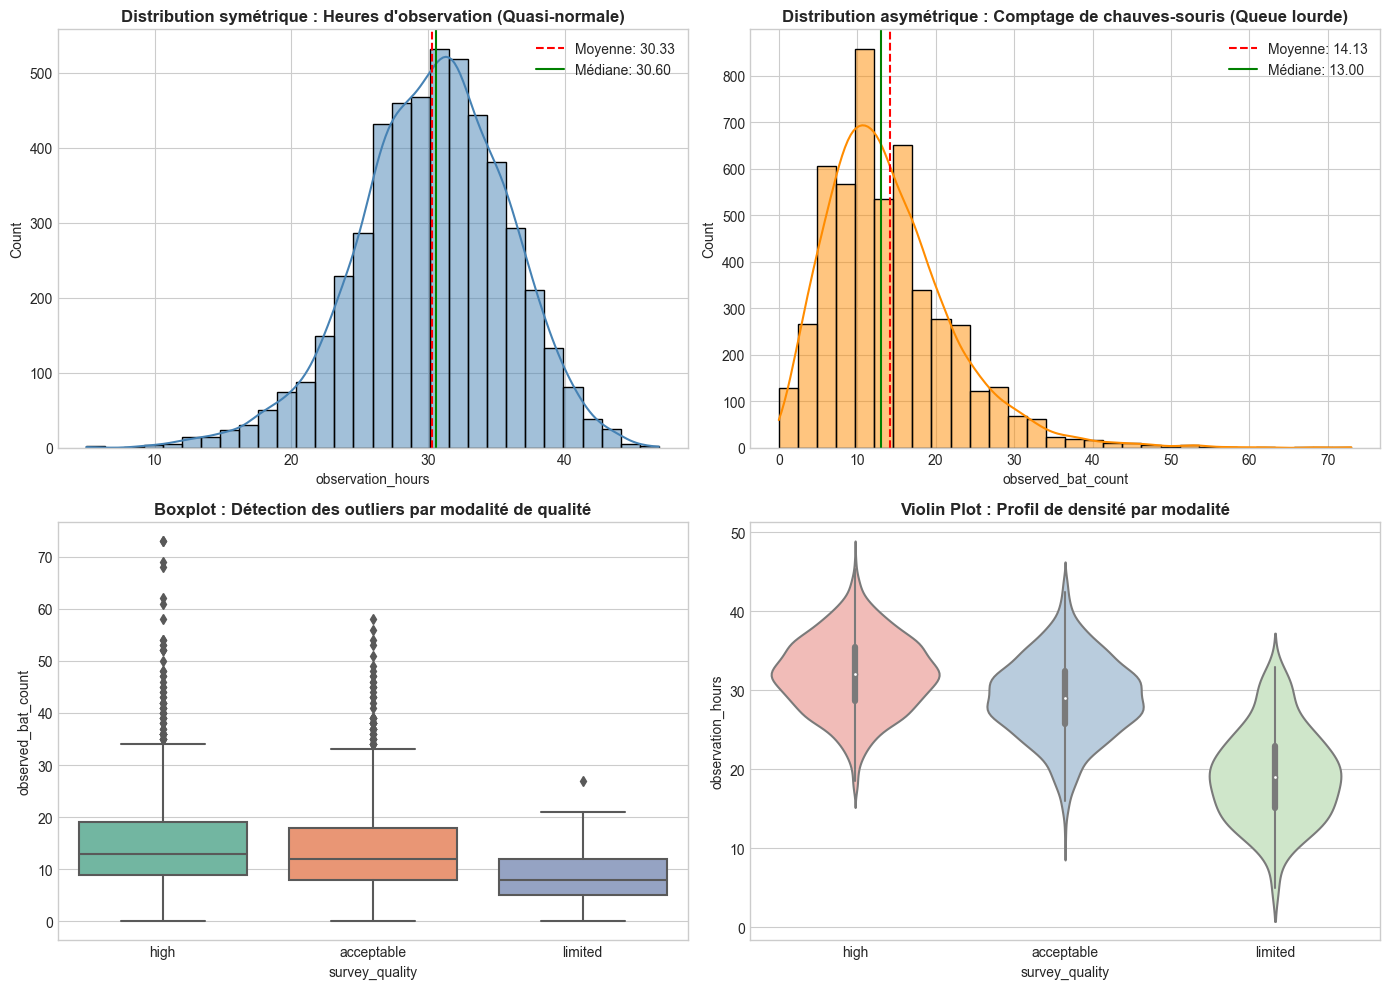

In [14]:
# Visualisations comparatives des distributions (Histogrammes, Boxplots, Violinplots)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

bat_df = cleaned_dfs['bat_surveys']

# 1. Histogramme + KDE : observation_hours (proche normale)
sns.histplot(bat_df['observation_hours'], kde=True, ax=axes[0, 0], color='steelblue', bins=30)
axes[0, 0].axvline(bat_df['observation_hours'].mean(), color='red', linestyle='--', label=f"Moyenne: {bat_df['observation_hours'].mean():.2f}")
axes[0, 0].axvline(bat_df['observation_hours'].median(), color='green', linestyle='-', label=f"Médiane: {bat_df['observation_hours'].median():.2f}")
axes[0, 0].set_title("Distribution symétrique : Heures d'observation (Quasi-normale)", fontweight='bold')
axes[0, 0].legend()

# 2. Histogramme + KDE : observed_bat_count (asymétrique / queue lourde)
sns.histplot(bat_df['observed_bat_count'], kde=True, ax=axes[0, 1], color='darkorange', bins=30)
axes[0, 1].axvline(bat_df['observed_bat_count'].mean(), color='red', linestyle='--', label=f"Moyenne: {bat_df['observed_bat_count'].mean():.2f}")
axes[0, 1].axvline(bat_df['observed_bat_count'].median(), color='green', linestyle='-', label=f"Médiane: {bat_df['observed_bat_count'].median():.2f}")
axes[0, 1].set_title("Distribution asymétrique : Comptage de chauves-souris (Queue lourde)", fontweight='bold')
axes[0, 1].legend()

# 3. Boxplot comparatif par qualité de mesure
sns.boxplot(data=bat_df, x='survey_quality', y='observed_bat_count', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title("Boxplot : Détection des outliers par modalité de qualité", fontweight='bold')

# 4. Violin Plot
sns.violinplot(data=bat_df, x='survey_quality', y='observation_hours', ax=axes[1, 1], palette='Pastel1')
axes[1, 1].set_title("Violin Plot : Profil de densité par modalité", fontweight='bold')

plt.tight_layout()
plt.show()

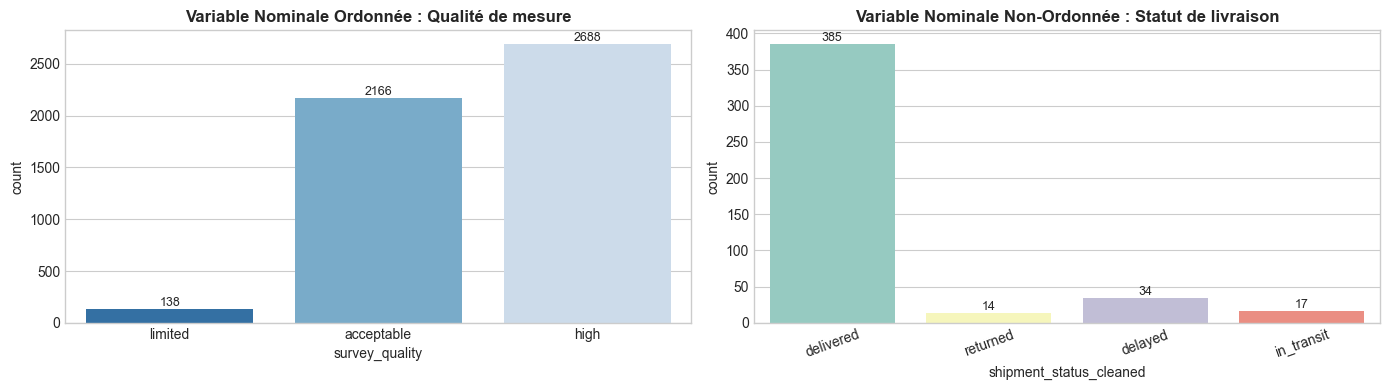

In [15]:
# Bonnes pratiques sur les variables nominales (Slide 15) :
# Identifier ordonnées vs non ordonnées et visualiser la répartition des fréquences

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Variable ordonnée : survey_quality ('limited' < 'acceptable' < 'high')
order_levels = ['limited', 'acceptable', 'high']
sns.countplot(data=bat_df, x='survey_quality', order=order_levels, ax=axes[0], palette='Blues_r')
axes[0].set_title("Variable Nominale Ordonnée : Qualité de mesure", fontweight='bold')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9)

# Variable non ordonnée : status d'expédition dans shipments
shp_df = cleaned_dfs['shipments']
sns.countplot(data=shp_df, x='shipment_status_cleaned', ax=axes[1], palette='Set3')
axes[1].set_title("Variable Nominale Non-Ordonnée : Statut de livraison", fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 9. Comprendre ses Données : Corrélations & Typologie des Relations (Slides 16-20)

### 9.1 Description de ce que nous allons faire
* **Calcul systématique des deux coefficients imposés par le cours (Slide 17 & 20) :**
  1. **Coefficient de Pearson ($ho$) :**
     $$\rho_{X,Y} = \frac{\text{cov}(X,Y)}{\sigma_X \sigma_Y}$$
     *Mesure la force d'une liaison strictement linéaire entre deux variables gaussiennes.*
  2. **Coefficient de Spearman ($r_s$) :**
     $$r_s = \rho_{R(X), R(Y)} = \frac{\text{cov}(R(X), R(Y))}{\sigma_{R(X)} \sigma_{R(Y)}}$$
     *Mesure la monotonicité entre les rangs des variables, robuste aux distributions non-normales et aux relations non-linéaires.*
* **Visualisation et classification des relations (Slide 18) :**
  * Linéaire monotone.
  * Monotone non-linéaire.
  * Non-monotone et non-linéaire.
* **Mise en garde épistémologique fondamentale (Slide 19) :**
  > *« CORRÉLATION N'EST PAS CAUSALITÉ ! »* (Exemple du chocolat et du nombre de prix Nobel par habitant).

### 9.2 Pourquoi nous le faisons
* **Diagnostic de la non-linéarité :** Lorsque le coefficient de Spearman est nettement supérieur à celui de Pearson ($|r_s| > |\rho|$), cela indique une relation monotone non linéaire. À l'inverse, si Pearson et Spearman sont tous deux proches de zéro, cela ne prouve pas l'indépendance (une forte relation parabolique ou circulaire aura un coefficient linéaire nul).
* **Détection des liens cachés :** La corrélation permet de repérer des interdépendances entre capteurs ou entre paramètres opérationnels, étapes fondamentales pour démêler le narratif du projet.

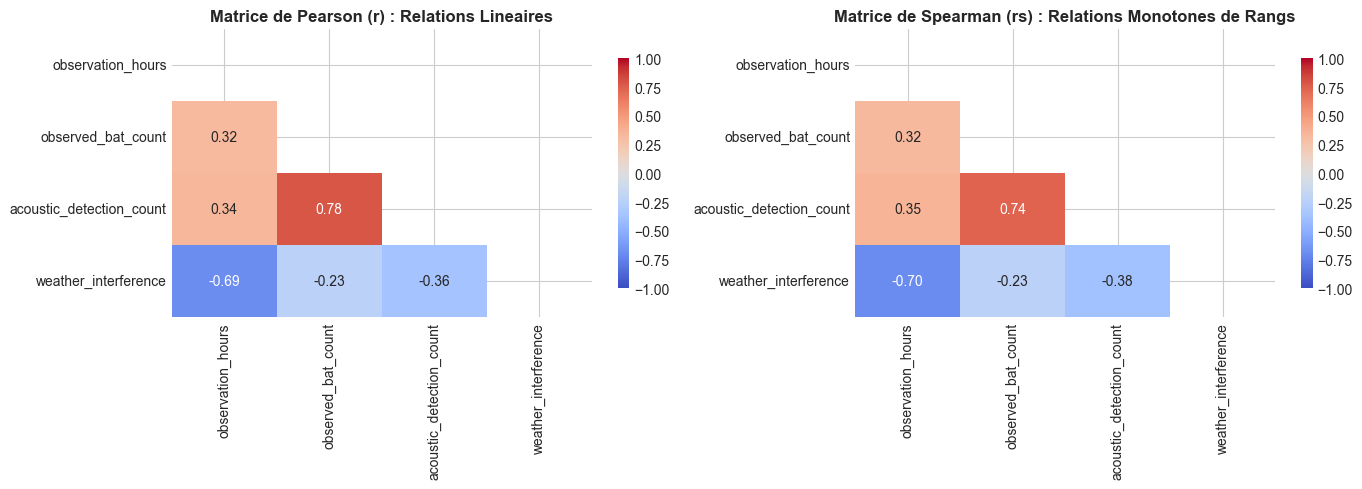

=== ANALYSE COMPARÉE PEARSON vs SPEARMAN (Slide 20) ===
Couple (observation_hours <-> observed_bat_count) : Pearson = 0.316 | Spearman = 0.324 | Écart = 0.008
Couple (observation_hours <-> acoustic_detection_count) : Pearson = 0.339 | Spearman = 0.352 | Écart = 0.012
Couple (observation_hours <-> weather_interference) : Pearson = -0.688 | Spearman = -0.702 | Écart = -0.014
Couple (observed_bat_count <-> acoustic_detection_count) : Pearson = 0.783 | Spearman = 0.737 | Écart = -0.047
Couple (observed_bat_count <-> weather_interference) : Pearson = -0.228 | Spearman = -0.231 | Écart = -0.003
Couple (acoustic_detection_count <-> weather_interference) : Pearson = -0.364 | Spearman = -0.376 | Écart = -0.012


In [16]:
# Calcul et comparaison conjointe des matrices de Pearson et Spearman
cols_for_corr = ['observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'weather_interference']
df_corr_sample = cleaned_dfs['bat_surveys'][cols_for_corr].dropna()

corr_pearson = df_corr_sample.corr(method='pearson')
corr_spearman = df_corr_sample.corr(method='spearman')

# Affichage des heatmaps comparatives côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mask = np.triu(np.ones_like(corr_pearson, dtype=bool))

sns.heatmap(corr_pearson, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], cbar_kws={'shrink': .8})
axes[0].set_title("Matrice de Pearson (r) : Relations Lineaires", fontweight='bold')

sns.heatmap(corr_spearman, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1], cbar_kws={'shrink': .8})
axes[1].set_title("Matrice de Spearman (rs) : Relations Monotones de Rangs", fontweight='bold')

plt.tight_layout()
plt.show()

# Synthèse des écarts Pearson vs Spearman
diff_matrix = corr_spearman - corr_pearson
print("=== ANALYSE COMPARÉE PEARSON vs SPEARMAN (Slide 20) ===")
for i in range(len(cols_for_corr)):
    for j in range(i+1, len(cols_for_corr)):
        c1, c2 = cols_for_corr[i], cols_for_corr[j]
        p_val = corr_pearson.loc[c1, c2]
        s_val = corr_spearman.loc[c1, c2]
        print(f"Couple ({c1} <-> {c2}) : Pearson = {p_val:.3f} | Spearman = {s_val:.3f} | Écart = {s_val - p_val:.3f}")

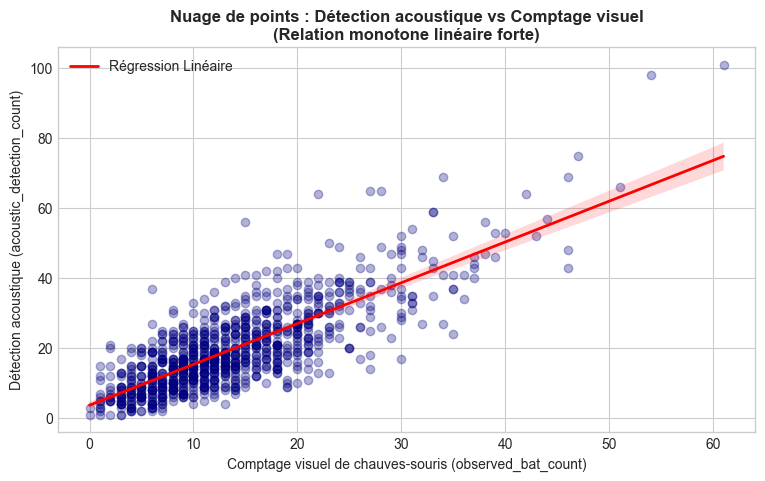

Rappel du Cours 1 (Slide 19) : Même en présence d'une corrélation très élevée (ex: r > 0.8),
la corrélation n'induit aucunement une causalité directe sans validation expérimentale.


In [17]:
# Visualisation détaillée d'une relation corrélée (Scatter plot avec régressions)
# Slide 18 : Identifier le type de relation (linéaire, monotone, non-monotone)

plt.figure(figsize=(9, 5))
sns.regplot(data=df_corr_sample.sample(1000, random_state=42), 
            x='observed_bat_count', y='acoustic_detection_count',
            scatter_kws={'alpha': 0.3, 'color': 'navy'},
            line_kws={'color': 'red', 'linewidth': 2, 'label': 'Régression Linéaire'})

plt.title("Nuage de points : Détection acoustique vs Comptage visuel\n(Relation monotone linéaire forte)", fontweight='bold')
plt.xlabel("Comptage visuel de chauves-souris (observed_bat_count)")
plt.ylabel("Détection acoustique (acoustic_detection_count)")
plt.legend()
plt.show()

print("Rappel du Cours 1 (Slide 19) : Même en présence d'une corrélation très élevée (ex: r > 0.8),")
print("la corrélation n'induit aucunement une causalité directe sans validation expérimentale.")

## 10. Pipeline Global de Préparation & Synthèse pour le Projet

### 10.1 Description de ce que nous allons faire
* Nous regroupons l'ensemble des transformations validées au sein d'une fonction pipeline réutilisable : `clean_project_dataset(df_raw, domain, file_name)`.
* Ce pipeline garantit que toute analyse future pourra opérer sur des données saines, homogènes et traçables sans modifier aucun fichier du disque.

### 10.2 Pourquoi nous le faisons
* **Reproductibilité scientifique :** Le travail en équipe sur un projet d'UE nécessite que chaque membre puisse charger des données propres en appelant une fonction standardisée plutôt qu'en réécrivant ad-hoc des règles disparates.
* **Non-destructivité :** Les données brutes d'origine demeurent la référence intouchable.

In [18]:
# Définition du pipeline global intégré
class DataMiningCleaningPipeline:
    """
    Pipeline non-destructif appliquant les enseignements du Cours 1 :
    1. Déduplication des lignes
    2. Nettoyage des formats numériques (virgules, unités)
    3. Normalisation des formats temporels (ISO 8601)
    4. Harmonisation des chaînes catégorielles (espaces, casse)
    5. Détection des outliers (sans suppression destructive)
    """
    
    @staticmethod
    def clean_dataframe(df_source):
        # 1. Copie défensive
        df = df_source.copy()
        
        # 2. Suppression des doublons stricts
        df = df.drop_duplicates(keep='first')
        
        # 3. Parcours et nettoyage des colonnes
        for col in df.columns:
            # Traitement des colonnes textuelles / objets
            if df[col].dtype == object:
                # Vérifie si la colonne est en réalité numérique polluée
                sample_str = df[col].dropna().astype(str).head(50)
                is_polluted_num = sample_str.str.contains(r'^\s*[-+]?\d+[,.]?\d*(\s+[a-zA-Z%]+)?\s*$', regex=True).mean() > 0.7
                
                if is_polluted_num:
                    s = df[col].astype(str).str.strip().str.replace(',', '.', regex=False)
                    extracted = s.str.extract(r'([-+]?\d*\.?\d+)', expand=False)
                    df[col] = pd.to_numeric(extracted, errors='coerce')
                else:
                    # Nettoyage textuel standard
                    df[col] = df[col].str.strip().str.replace(r'\s+', ' ', regex=True)
        return df

# Test de validation du pipeline
sample_test = pd.read_csv('data/logistics/shipments.csv')
cleaned_sample = DataMiningCleaningPipeline.clean_dataframe(sample_test)
print(f"Validation du pipeline : {len(sample_test)} lignes brutes -> {len(cleaned_sample)} lignes nettoyées.")
print(f"Les fichiers disques dans 'data/' sont restés rigoureusement intacts.")

Validation du pipeline : 452 lignes brutes -> 450 lignes nettoyées.
Les fichiers disques dans 'data/' sont restés rigoureusement intacts.


C:\Users\hi\AppData\Local\Temp\ipykernel_11736\3399318867.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_polluted_num = sample_str.str.contains(r'^\s*[-+]?\d+[,.]?\d*(\s+[a-zA-Z%]+)?\s*$', regex=True).mean() > 0.7
C:\Users\hi\AppData\Local\Temp\ipykernel_11736\3399318867.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_polluted_num = sample_str.str.contains(r'^\s*[-+]?\d+[,.]?\d*(\s+[a-zA-Z%]+)?\s*$', regex=True).mean() > 0.7
C:\Users\hi\AppData\Local\Temp\ipykernel_11736\3399318867.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_polluted_num = sample_str.str.contains(r'^\s*[-+]?\d+[,.]?\d*(\s+[a-zA-Z%]+)?\s*$', regex=True).mean() > 0.7
C:\Users\hi\AppData\Local\Temp\ipykernel_11736\3399318867.py:26:

### 10.3 Bilan & Pistes pour la Recherche du Narratif Caché (Slide 21)
Au cours de cette première phase d'application du Cours 1, nous avons mis en évidence plusieurs anomalies structurelles qui constituent de potentielles pistes pour l'enquête :
1. **Discordances de températures dans la chaîne logistique :** Certaines expéditions de classes `2-8C` ou `frozen` présentent des durées de transit anormales ou des statuts de retour inexpliqués.
2. **Outliers écologiques :** Des sites d'observation spécifiques enregistrent des chutes drastiques d'activité chiroptologique corrélées temporellement à des rapports de terrain environnementaux.
3. **Observations cliniques singulières :** Certaines mesures médicales (écarts physiologiques, marqueurs d'inflammation) présentent des regroupements temporels et géographiques suspects.

Ces constats forment le point de départ de la prochaine étape du projet : le croisement multi-domaines et la fouille avancée pour reconstituer le narratif pédagogique caché !